In [47]:
# Import des bibliothèques

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import welch
from sklearn.decomposition import FastICA

In [36]:
Mat1 = np.zeros((4,2))
print(Mat1.shape)

Mat2 = np.zeros((2,300000))
print(Mat2.shape)

print(np.dot(Mat1,Mat2).shape)


(4, 2)
(2, 300000)
(4, 300000)


In [21]:
# Récupération des données

# Les données sont contenues dans le dossier csv 
# r0X = 4 enregistrements abdominaux en fonction du temps (1 par colonne) avec X la patiente prise en charge + 1 enregistrement foetal direct
# qrs = 1 jeu d'annotations en fonction du temps, par X, tous dans la même colonne
# channels = métadonnées des enregistrements
fichier = Path("csv")

# Par exemple, 'r01' a 5 colonnes : t_s ; Direct_1, Abdomen_1, Abdomen_2, Abdomen_3, Abdomen_4
signaux = {f.stem: pd.read_csv(f) for f in sorted(fichier.glob("r*.csv"))}

# qrs : enregistrement ; sample ; ts
qrs = pd.read_csv(fichier / "qrs.csv")

# channels : enregistrement ; channel ; unit ; fs ; sensor_type ; prefiltering
channels = pd.read_csv(fichier / "channels.csv")

# La fréquence d'échantillonnage est la même pour tous les signaux, qu'ils soient Directs ou abdominaux
# Seules la fréquence d'échantillonnage des annotations varie, on règle ça plus loin
fs = channels["fs"].iloc[0]

In [4]:
print(fs)

1000.0


In [5]:
# Zoom sur la matrice d'observations du premier enregistrement

abdomen = ["Abdomen_1", "Abdomen_2", "Abdomen_3", "Abdomen_4"]

# C'est du 4 x N avec N = 30000 pour tous les enregistrements
X01 = signaux["r01"][abdomen].to_numpy().T

In [6]:
print(X01.shape)

display(pd.DataFrame(X01[:, :6], index=[f"x{i + 1} = {c}" for i, c in enumerate(abdomen)], columns=[f"t = {k}" for k in range(6)]).round(2))

(4, 300000)


,t = 0,t = 1,t = 2,t = 3,t = 4,t = 5
x1 = Abdomen_1,-8.85,-13.95,-18.75,-23.45,-27.95,-32.85
x2 = Abdomen_2,13.35,12.65,12.05,11.45,10.45,8.65
x3 = Abdomen_3,22.05,21.75,21.25,20.25,18.55,15.95
x4 = Abdomen_4,32.55,35.35,37.55,38.95,39.45,39.25


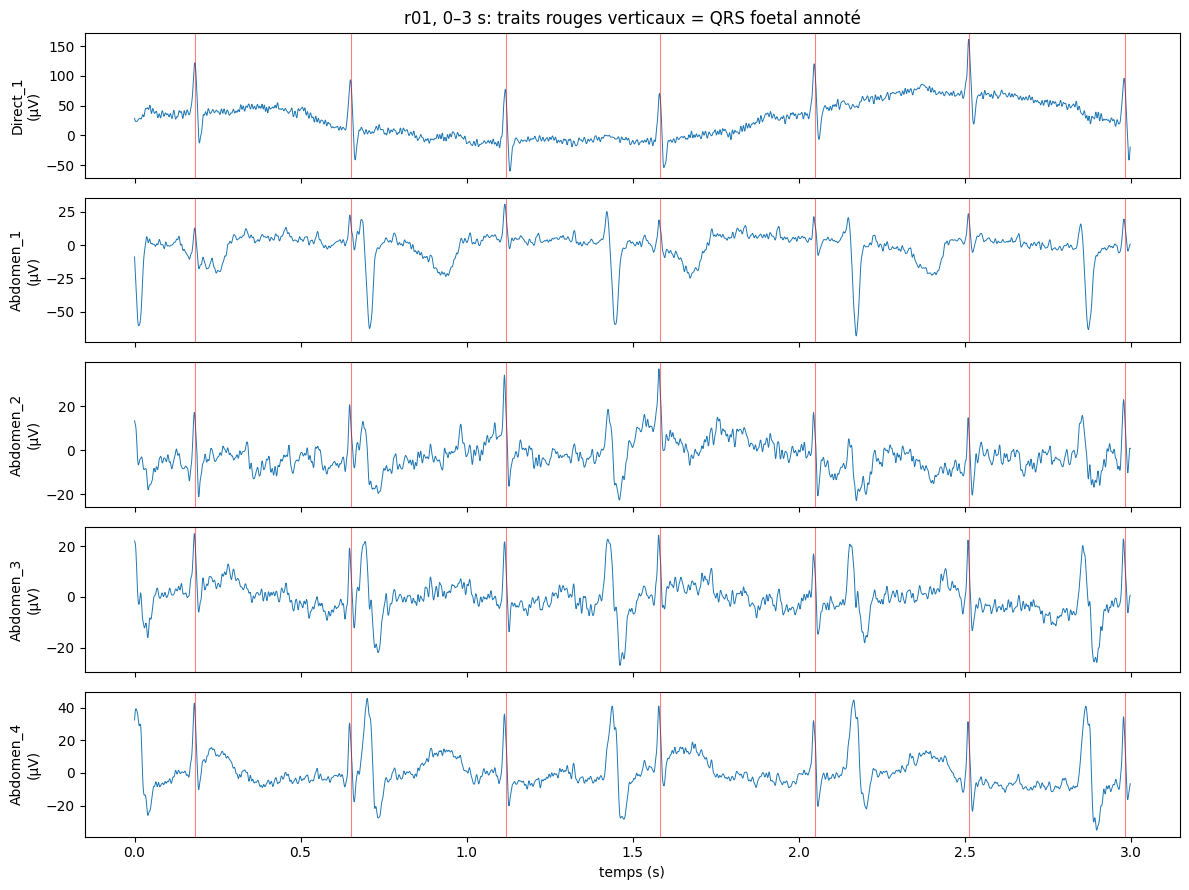

In [43]:
# Affichage de la matrice d'observations du premier enregistrement : 
# ???????
enregistrement, t_debut, t_final = "r01", 0, 3 # Jouer ici sur les dates pour visualiser des fenêtes plus courtes
df = signaux[enregistrement]
window = df[(df["t_s"] >= t_debut) & (df["t_s"] < t_debut + t_final)]
qrs_window = qrs[(qrs["record"] == enregistrement) & (qrs["t_s"] >= t_debut) & (qrs["t_s"] < t_debut + t_final)]

channel_names = list(df.columns[1:])
fig, axes = plt.subplots(len(channel_names), 1, figsize=(12, 9), sharex=True)
for ax, ch in zip(axes, channel_names): # prend les couples (axe, channel) un par un
    ax.plot(window["t_s"], window[ch], linewidth=0.7)
    # On fait apparaître des lignes verticales qui correspondent aux annotations des experts sur Direct_1
    ax.vlines(qrs_window["t_s"], 0, 1, transform=ax.get_xaxis_transform(), color="red", linewidth=0.8, alpha=0.5)
    ax.set_ylabel(f"{ch}\n(µV)")
axes[0].set_title(f"{enregistrement}, {t_debut}–{t_debut + t_final} s: traits rouges verticaux = QRS foetal annoté")
axes[-1].set_xlabel("temps (s)")
plt.tight_layout()
plt.show() 



In [44]:
# On Découpe X01 en 5 fenêtres de 15 s, choisies dans les zones calmes de r01

duree = 15                          
debuts = [10, 30, 135, 255, 280]    
n = int(duree * fs)                 # nombre d'échantillons par fenêtre (fs est un flottant)

# Dictionnaire {t0: matrice 4 x n} 
fenetres = {}
for t0 in debuts:
    k0 = int(t0 * fs)               # colonne de X01 correspondant à l'instant t0
    fenetres[t0] = X01[:, k0 : k0 + n]

# QRS annotés de chaque fenêtre
qrs_r01 = qrs[qrs["record"] == "r01"]["t_s"].to_numpy()
qrs_fenetres = {t0: qrs_r01[(qrs_r01 >= t0) & (qrs_r01 < t0 + duree)] - t0 for t0 in debuts}

for t0 in debuts:
    print(f"{t0:3d}-{t0 + duree:3d} s : forme {fenetres[t0].shape}, {len(qrs_fenetres[t0])} QRS annotés")


 10- 25 s : forme (4, 15000), 32 QRS annotés
 30- 45 s : forme (4, 15000), 32 QRS annotés
135-150 s : forme (4, 15000), 32 QRS annotés
255-270 s : forme (4, 15000), 31 QRS annotés
280-295 s : forme (4, 15000), 31 QRS annotés


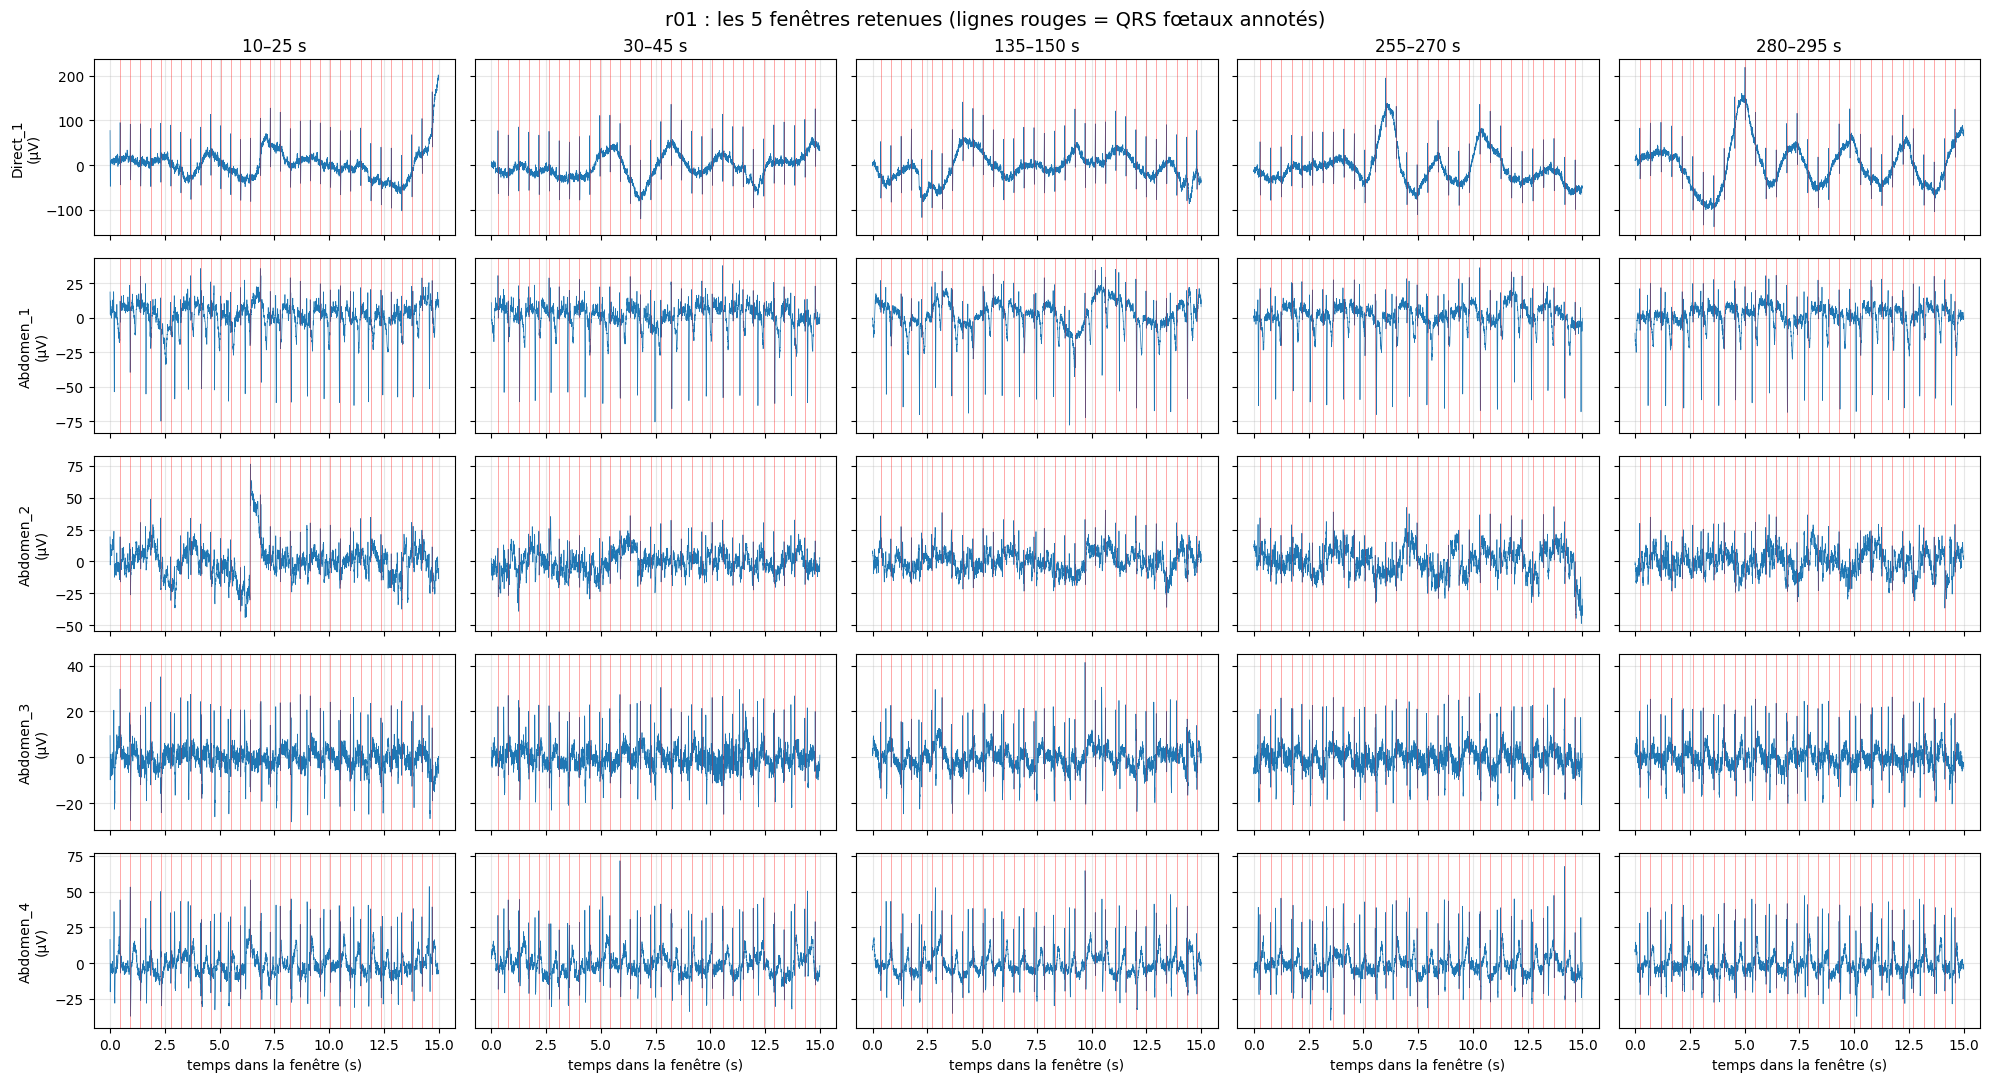

In [45]:
# Fourni par Claude

# Grille des fenêtres : une colonne par fenêtre, une ligne par voie (Direct_1 en référence, puis les 4 voies abdominales)

direct = signaux["r01"]["Direct_1"].to_numpy()
voies = ["Direct_1"] + abdomen
t = np.arange(n) / fs                       # temps propre de chaque fenêtre, de 0 à 15 s

fig, axes = plt.subplots(len(voies), len(debuts), figsize=(20, 11), sharex=True, sharey="row")

for j, t0 in enumerate(debuts):
    k0 = int(t0 * fs)
    signaux_fenetre = np.vstack([direct[k0 : k0 + n], fenetres[t0]])   # 5 x n

    for i, voie in enumerate(voies):
        ax = axes[i, j]
        ax.plot(t, signaux_fenetre[i], linewidth=0.5, color="tab:blue")
        ax.vlines(qrs_fenetres[t0], 0, 1, transform=ax.get_xaxis_transform(),
                  color="red", linewidth=0.6, alpha=0.4)
        ax.grid(alpha=0.3)

        if i == 0:
            ax.set_title(f"{t0}–{t0 + duree} s")
        if j == 0:
            ax.set_ylabel(f"{voie}\n(µV)")
        if i == len(voies) - 1:
            ax.set_xlabel("temps dans la fenêtre (s)")

fig.suptitle("r01 : les 5 fenêtres retenues (lignes rouges = QRS fœtaux annotés)", fontsize=14)
plt.tight_layout()
plt.show()

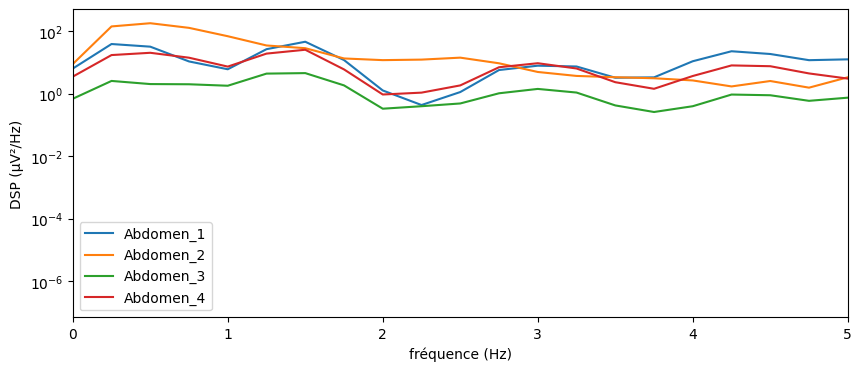

In [46]:
# Zoom sur la première mini matrice

X01_1 = fenetres[10]

# Contenu fréquentiel de la fenêtre X01_1, voie par voie

plt.figure(figsize=(10, 4))

for i in range(4):
    f, dsp = welch(X01_1[i], fs=fs, nperseg=4000)   
    plt.semilogy(f, dsp, label=abdomen[i])

plt.xlim(0,5)
plt.xlabel("fréquence (Hz)")
plt.ylabel("DSP (µV²/Hz)")
plt.legend()
plt.show()
